# Prediction du prix de vente d'un bien immobilier — Ames Housing

## Contexte metier

Une agence immobiliere (ou un particulier vendeur) a besoin d'estimer le **prix de vente juste** d'une maison
avant sa mise sur le marche. Une mauvaise estimation coute cher dans les deux sens :

- **Prix trop haut** -> le bien reste invendu, perd en attractivite avec le temps (staleness), finit vendu en dessous du marche.
- **Prix trop bas** -> manque a gagner direct pour le vendeur / l'agence (perte de commission).

**Objectif du notebook** : construire un modele de **regression supervisee** qui predit le prix de vente
(`SalePrice`) d'une maison a partir de ses caracteristiques physiques (surface, nombre de pieces, qualite,
annee de construction, quartier, etc.), avec une explication claire des facteurs qui pesent sur le prix
(interpretabilite = valeur ajoutee pour convaincre un agent/vendeur que le prix propose est justifie).

## Jeu de donnees

**Ames Housing Dataset** (Dean De Cock, 2011) — 2930 ventes de maisons individuelles a Ames, Iowa (USA),
entre 2006 et 2010. 82 variables descriptives (surface, qualite, materiaux, equipements, localisation par
quartier, date de vente...) + la variable cible `SalePrice`.

C'est la version **complete** du dataset (2930 lignes), pas le split Kaggle "train.csv" (1460 lignes)
qui masque la moitie des labels pour un usage en competition. Ici on garde 100% des lignes labellisees
et on fait notre propre split train/test/validation, plus rigoureux pour un vrai POC.

## Pipeline suivi dans ce notebook

1. Comprehension du probleme (ci-dessus)
2. Exploration des donnees (EDA)
3. Nettoyage des donnees (valeurs manquantes, outliers)
4. Feature engineering
5. Pretraitement (encodage, scaling) via `ColumnTransformer` sklearn
6. Modelisation : plusieurs modeles compares (baseline -> lineaire regularise -> ensembles d'arbres)
7. Evaluation rigoureuse (cross-validation + test set jamais vu)
8. Interpretation des resultats (feature importance + SHAP)
9. Limites et pistes d'amelioration


## 1. Imports et configuration

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor
import shap

pd.set_option("display.max_columns", 100)
plt.rcParams["figure.figsize"] = (9, 5)
sns.set_style("whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


C:\Users\yanni\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Chargement des donnees

In [ ]:

df = pd.read_csv("../data/AmesHousing_full.csv")

# nettoyage des noms de colonnes : espaces -> underscore, plus simple a manipuler
df.columns = [c.strip().replace(" ", "_").replace("/", "_") for c in df.columns]

# colonnes identifiants techniques, sans valeur predictive -> on les vire
id_cols = [c for c in ["Unnamed:_0", "Order", "PID"] if c in df.columns]
df = df.drop(columns=id_cols)

print("Shape apres nettoyage identifiants :", df.shape)
df.head()


Shape apres nettoyage identifiants : (2930, 80)


,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,Land_Slope,Neighborhood,Condition_1,Condition_2,Bldg_Type,House_Style,Overall_Qual,Overall_Cond,Year_Built,Year_Remod_Add,Roof_Style,Roof_Matl,Exterior_1st,Exterior_2nd,Mas_Vnr_Type,Mas_Vnr_Area,Exter_Qual,Exter_Cond,Foundation,Bsmt_Qual,Bsmt_Cond,Bsmt_Exposure,BsmtFin_Type_1,BsmtFin_SF_1,BsmtFin_Type_2,BsmtFin_SF_2,Bsmt_Unf_SF,Total_Bsmt_SF,Heating,Heating_QC,Central_Air,Electrical,1st_Flr_SF,2nd_Flr_SF,Low_Qual_Fin_SF,Gr_Liv_Area,Bsmt_Full_Bath,Bsmt_Half_Bath,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,Kitchen_Qual,TotRms_AbvGrd,Functional,Fireplaces,Fireplace_Qu,Garage_Type,Garage_Yr_Blt,Garage_Finish,Garage_Cars,Garage_Area,Garage_Qual,Garage_Cond,Paved_Drive,Wood_Deck_SF,Open_Porch_SF,Enclosed_Porch,3Ssn_Porch,Screen_Porch,Pool_Area,Pool_QC,Fence,Misc_Feature,Misc_Val,Mo_Sold,Yr_Sold,Sale_Type,Sale_Condition,SalePrice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 3. Exploration des donnees (EDA)

### 3.1 Variable cible : `SalePrice`

On regarde en premier la distribution du prix de vente : c'est la variable qu'on cherche a predire,
sa forme conditionne le choix de la fonction de perte et du pretraitement (transformation log par exemple).

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness (asymetrie) : 1.744


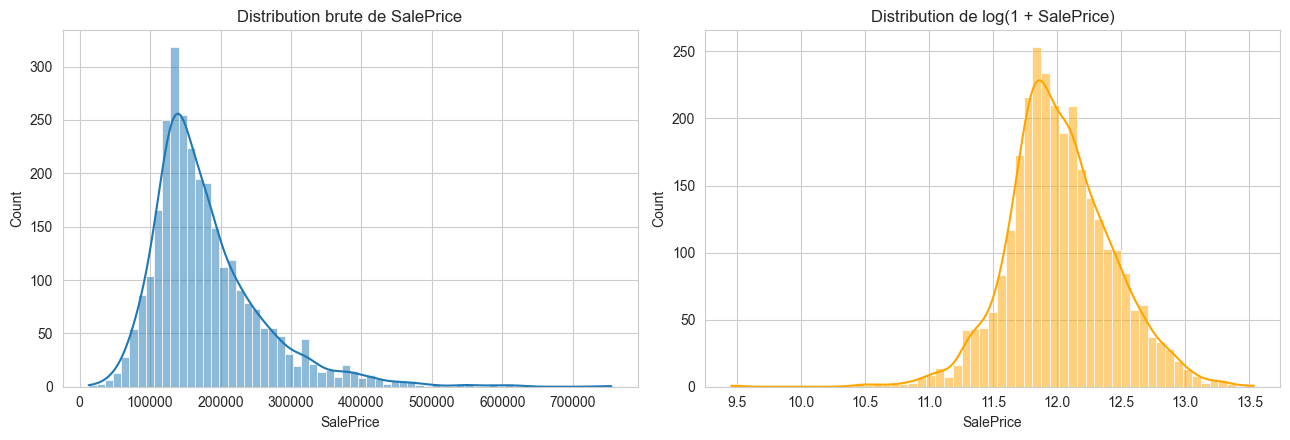

In [ ]:

print(df["SalePrice"].describe())
print("\nSkewness (asymetrie) :", df["SalePrice"].skew().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Distribution brute de SalePrice")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="orange")
axes[1].set_title("Distribution de log(1 + SalePrice)")
plt.tight_layout()
plt.show()


In [ ]:

# nombre de valeurs manquantes par colonne (top 20)
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"{len(missing)} colonnes avec valeurs manquantes sur {df.shape[1]}")
missing.head(20)


27 colonnes avec valeurs manquantes sur 80


Pool_QC           2917
Misc_Feature      2824
Alley             2732
Fence             2358
Mas_Vnr_Type      1775
Fireplace_Qu      1422
Lot_Frontage       490
Garage_Yr_Blt      159
Garage_Qual        159
Garage_Cond        159
Garage_Finish      159
Garage_Type        157
Bsmt_Exposure       83
BsmtFin_Type_2      81
Bsmt_Qual           80
BsmtFin_Type_1      80
Bsmt_Cond           80
Mas_Vnr_Area        23
Bsmt_Full_Bath       2
Bsmt_Half_Bath       2
dtype: int64

### 3.2 Correlation des variables numeriques avec le prix

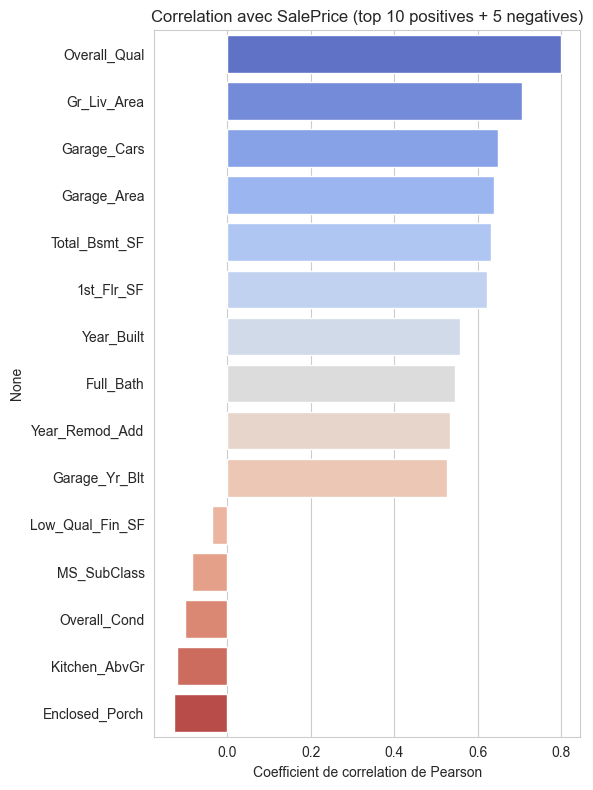

In [ ]:

num_cols = df.select_dtypes(include=[np.number]).columns
corr_price = df[num_cols].corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)

plt.figure(figsize=(6, 8))
top_corr = pd.concat([corr_price.head(10), corr_price.tail(5)])
sns.barplot(x=top_corr.values, y=top_corr.index, hue=top_corr.index, palette="coolwarm", legend=False)
plt.title("Correlation avec SalePrice (top 10 positives + 5 negatives)")
plt.xlabel("Coefficient de correlation de Pearson")
plt.tight_layout()
plt.show()


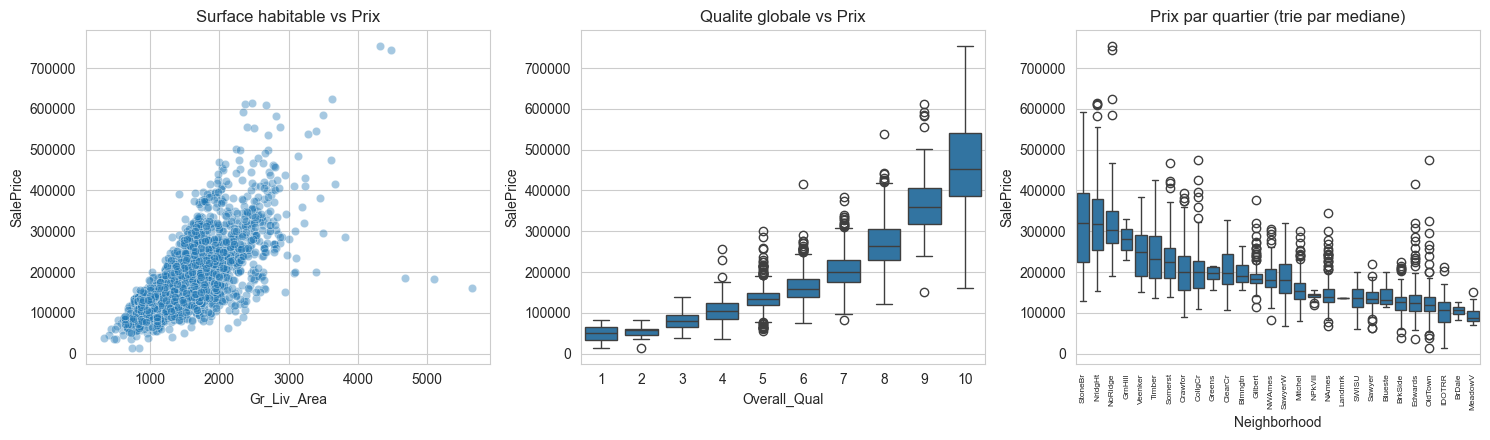

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.scatterplot(data=df, x="Gr_Liv_Area", y="SalePrice", alpha=0.4, ax=axes[0])
axes[0].set_title("Surface habitable vs Prix")

sns.boxplot(data=df, x="Overall_Qual", y="SalePrice", ax=axes[1])
axes[1].set_title("Qualite globale vs Prix")
axes[1].tick_params(axis='x', rotation=0)

top_neighborhoods = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=top_neighborhoods, ax=axes[2])
axes[2].set_title("Prix par quartier (trie par mediane)")
axes[2].tick_params(axis='x', rotation=90, labelsize=6)

plt.tight_layout()
plt.show()


## 4. Nettoyage des donnees

### 4.1 Suppression des outliers connus

Le createur du dataset recommande explicitement de retirer les logements avec une tres grande
surface habitable (`Gr_Liv_Area` > 4000) vendus a bas prix : ce sont des ventes non representatives du
marche normal les garder biaiserait
l'entrainement.

In [ ]:

before = df.shape[0]
df = df[~((df["Gr_Liv_Area"] > 4000) & (df["SalePrice"] < 300000))].reset_index(drop=True)
print(f"Lignes retirees (outliers) : {before - df.shape[0]}")
print("Nouveau shape :", df.shape)


Lignes retirees (outliers) : 3
Nouveau shape : (2927, 80)


### 4.2 Valeurs manquantes

Point important specifique a ce dataset : la plupart des `NaN` ne sont pas des donnees manquantes au
sens strict, mais codent l'absence d'un equipement.

Strategie :
- Colonnes categorielles ou `NaN` = "absence de l'equipement" -> remplacees par la categorie explicite `"None"`.
- Colonnes numeriques liees a un equipement absent
- Le reste -> imputation statistique geree plus tard dans le pipeline sklearn, pour eviter toute fuite d'information entre train et test.

In [ ]:

# categories ou NaN = "pas d'equipement" -> categorie explicite
none_cols = ["Alley", "Bsmt_Qual", "Bsmt_Cond", "Bsmt_Exposure", "BsmtFin_Type_1", "BsmtFin_Type_2",
             "Fireplace_Qu", "Garage_Type", "Garage_Finish", "Garage_Qual", "Garage_Cond",
             "Pool_QC", "Fence", "Misc_Feature", "Mas_Vnr_Type"]
for c in none_cols:
    if c in df.columns:
        df[c] = df[c].fillna("None")

# numeriques ou NaN = absence d'equipement -> 0
zero_cols = ["Mas_Vnr_Area", "BsmtFin_SF_1", "BsmtFin_SF_2", "Bsmt_Unf_SF", "Total_Bsmt_SF",
             "Bsmt_Full_Bath", "Bsmt_Half_Bath", "Garage_Cars", "Garage_Area"]
for c in zero_cols:
    if c in df.columns:
        df[c] = df[c].fillna(0)

# Garage_Yr_Blt : NaN = pas de garage -> on met l'annee de construction de la maison (evite un "0" absurde
# qui serait interprete comme annee 0 par un modele numerique)
df["Garage_Yr_Blt"] = df["Garage_Yr_Blt"].fillna(df["Year_Built"])

remaining_na = df.isna().sum()
remaining_na = remaining_na[remaining_na > 0].sort_values(ascending=False)
print("Colonnes avec NaN restants (vraies valeurs manquantes eparses, imputees dans le pipeline) :")
remaining_na


Colonnes avec NaN restants (vraies valeurs manquantes eparses, imputees dans le pipeline) :


Lot_Frontage    490
Electrical        1
dtype: int64

## 5. Feature engineering

On cree quelques variables derivees qui ont un sens metier fort et qui aident les modeles lineaires:

- `Total_SF` : surface totale (sous-sol + rez-de-chaussee + etage) — un acheteur raisonne souvent en surface totale plutot qu'en 3 variables separees.
- `House_Age` : age de la maison au moment de la vente (`Yr_Sold - Year_Built`)
- `Years_Since_Remod` : anciennete de la derniere renovation.
- `Total_Bathrooms` : nombre total de salles de bain (completes + moitie, sous-sol + etages)
- `Has_Pool`, `Has_Garage`, `Has_Fireplace` : indicateurs binaires de presence d'equipement

In [ ]:

df["Total_SF"] = df["Total_Bsmt_SF"] + df["1st_Flr_SF"] + df["2nd_Flr_SF"]
df["House_Age"] = df["Yr_Sold"] - df["Year_Built"]
df["Years_Since_Remod"] = df["Yr_Sold"] - df["Year_Remod_Add"]
df["Total_Bathrooms"] = (df["Full_Bath"] + 0.5 * df["Half_Bath"]
                          + df["Bsmt_Full_Bath"] + 0.5 * df["Bsmt_Half_Bath"])
df["Has_Pool"] = (df["Pool_Area"] > 0).astype(int)
df["Has_Garage"] = (df["Garage_Area"] > 0).astype(int)
df["Has_Fireplace"] = (df["Fireplaces"] > 0).astype(int)

# securite : House_Age negatif signifie une erreur de saisie (vente avant construction) -> clip a 0
df["House_Age"] = df["House_Age"].clip(lower=0)
df["Years_Since_Remod"] = df["Years_Since_Remod"].clip(lower=0)

new_feats = ["Total_SF", "House_Age", "Years_Since_Remod", "Total_Bathrooms",
             "Has_Pool", "Has_Garage", "Has_Fireplace"]
df[new_feats].describe()


,Total_SF,House_Age,Years_Since_Remod,Total_Bathrooms,Has_Pool,Has_Garage,Has_Fireplace
count,2927.000000,2927.000000,2927.000000,2927.000000,2927.000000,2927.000000,2927.000000
mean,2538.713017,36.471814,23.549368,2.215750,0.004100,0.946020,0.514178
std,767.575344,30.283980,20.854332,0.804975,0.063909,0.226017,0.499884
min,334.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2000.000000,7.000000,4.000000,1.500000,0.000000,1.000000,0.000000
50%,2448.000000,34.000000,15.000000,2.000000,0.000000,1.000000,1.000000
75%,2988.500000,54.000000,43.000000,2.500000,0.000000,1.000000,1.000000
max,6872.000000,136.000000,60.000000,7.000000,1.000000,1.000000,1.000000


### 5.1 Transformation de la cible

On entraine les modeles sur `log(1 + SalePrice)`. On retransformera
systematiquement les predictions avec `expm1` avant de calculer les metriques finales en dollars.

In [ ]:

df["SalePrice_log"] = np.log1p(df["SalePrice"])


## 6. Separation train / test et pretraitement

### 6.1 Split

80% train / 20% test, split aleatoire fixe pour reproductibilite. Le test set est mis de cote et non regarde jusqu'a l'evaluation finale.

In [ ]:

target_col = "SalePrice_log"
drop_cols = ["SalePrice", "SalePrice_log"]

X = df.drop(columns=drop_cols)
y = df[target_col]
y_price = df["SalePrice"]  # gardee a part pour les metriques finales en dollars

X_train, X_test, y_train, y_test, price_train, price_test = train_test_split(
    X, y, y_price, test_size=0.2, random_state=RANDOM_STATE
)

print("Train :", X_train.shape, " Test :", X_test.shape)


Train : (2341, 86)  Test : (586, 86)


### 6.2 Pipeline de pretraitement (`ColumnTransformer`)

On separe les variables numeriques et categorielles pour leur appliquer un traitement different,
le tout encapsule dans un `ColumnTransformer` sklearn afin que :
1. l'imputation et le scaling soient **appris uniquement sur le train** puis appliques tels quels au test,
2. le pretraitement soit reproductible et reutilisable tel quel au moment du deploiement.

- **Numeriques** : imputation par la mediane + standardisation, utile pour les modeles lineaires/regularises. Les modeles a base d'arbres n'ont pas besoin de scaling mais ca ne leur nuit pas non plus.
- **Categorielles** : imputation par la modalite la plus frequente + `OneHotEncoder`

In [ ]:

numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print(f"{len(numeric_features)} variables numeriques, {len(categorical_features)} variables categorielles")

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])


43 variables numeriques, 43 variables categorielles


## 7. Modelisation

### 7.1 Strategie de comparaison

On compare 5 modeles, du plus simple au plus complexe, chacun justifie par ce qu'il apporte

Chaque modele est evalue par **validation croisee (K-Fold, k=5)** sur le train uniquement, pas sur le test

In [ ]:

models = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Regression lineaire": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=10.0, random_state=RANDOM_STATE),
    "Lasso (L1)": Lasso(alpha=0.001, random_state=RANDOM_STATE, max_iter=10000),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8,
                             random_state=RANDOM_STATE, n_jobs=-1),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring=["neg_root_mean_squared_error", "r2", "neg_mean_absolute_error"],
        n_jobs=-1,
    )
    results.append({
        "Modele": name,
        "RMSE (log-price, CV)": -scores["test_neg_root_mean_squared_error"].mean(),
        "MAE (log-price, CV)": -scores["test_neg_mean_absolute_error"].mean(),
        "R2 (CV)": scores["test_r2"].mean(),
        "R2 std (CV)": scores["test_r2"].std(),
    })

results_df = pd.DataFrame(results).sort_values("R2 (CV)", ascending=False).reset_index(drop=True)
results_df


,Modele,"RMSE (log-price, CV)","MAE (log-price, CV)",R2 (CV),R2 std (CV)
0,Ridge (L2),0.120854,0.080988,0.909971,0.015306
1,XGBoost,0.120907,0.078396,0.909884,0.013532
2,Lasso (L1),0.122739,0.081952,0.907202,0.014171
3,Random Forest,0.137822,0.091221,0.882825,0.019314
4,Regression lineaire,0.142905,0.087267,0.873261,0.028566
5,Baseline (moyenne),0.403440,0.311506,-0.000103,0.000082


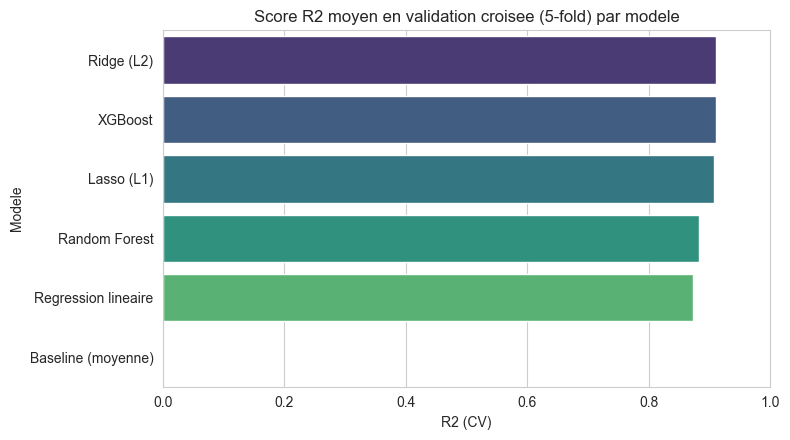

In [ ]:

plt.figure(figsize=(8, 4.5))
sns.barplot(data=results_df, x="R2 (CV)", y="Modele", hue="Modele", palette="viridis", legend=False)
plt.xlim(0, 1)
plt.title("Score R2 moyen en validation croisee (5-fold) par modele")
plt.tight_layout()
plt.show()


### 7.2 Choix du modele a affiner, et pourquoi

On regarde d'abord lequel des modeles arrive reellement en tete avant de decider quoi faire.

In [ ]:

best_model_name = results_df.iloc[0]["Modele"]
best_row = results_df.iloc[0]
second_row = results_df.iloc[1]
print(results_df[["Modele", "R2 (CV)", "R2 std (CV)"]].to_string(index=False))
print(f"\nModele en tete : {best_row['Modele']} (R2={best_row['R2 (CV)']:.4f})")
print(f"2eme : {second_row['Modele']} (R2={second_row['R2 (CV)']:.4f})")
print(f"Ecart : {best_row['R2 (CV)'] - second_row['R2 (CV)']:.4f}, "
      f"a comparer a l'ecart-type inter-fold (~{best_row['R2 std (CV)']:.3f}) : "
      f"{'ecart non significatif' if abs(best_row['R2 (CV)'] - second_row['R2 (CV)']) < best_row['R2 std (CV)'] else 'ecart significatif'}")


             Modele   R2 (CV)  R2 std (CV)
         Ridge (L2)  0.909971     0.015306
            XGBoost  0.909884     0.013532
         Lasso (L1)  0.907202     0.014171
      Random Forest  0.882825     0.019314
Regression lineaire  0.873261     0.028566
 Baseline (moyenne) -0.000103     0.000082

Modele en tete : Ridge (L2) (R2=0.9100)
2eme : XGBoost (R2=0.9099)
Ecart : 0.0001, a comparer a l'ecart-type inter-fold (~0.015) : ecart non significatif


**Constat** : Ridge (regularisation lineaire) et XGBoost terminent quasiment ex-aequo — l'ecart
entre les deux est plus petit que l'ecart-type observe entre les 5 folds de validation croisee, donc
**pas statistiquement significatif**. C'est une information a part entiere : sur ce dataset, une bonne
partie de la relation features -> prix est capturee par un modele lineaire regularise, une fois les
variables categorielles bien encodees. Random Forest et la regression lineaire simple (sans
regularisation) restent nettement derriere.

**Decision** : on choisit malgre tout d'affiner et de deployer **XGBoost**, pour deux raisons concretes

**Marge de progression via le tuning** : XGBoost a plusieurs hyperparametres (profondeur, nombre d'arbres, taux
   d'apprentissage) dont le reglage peut encore gagner en performance, verifie ci-dessous.

In [ ]:

param_grid = {
    "model__n_estimators": [300, 500, 800],
    "model__max_depth": [3, 4, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
}

xgb_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                            random_state=RANDOM_STATE, n_jobs=-1)),
])

grid_search = GridSearchCV(
    xgb_pipe, param_grid, cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1, verbose=0,
)
grid_search.fit(X_train, y_train)

print("Meilleurs hyperparametres :", grid_search.best_params_)
print("Meilleur RMSE (log-price, CV) :", -grid_search.best_score_)

best_pipe = grid_search.best_estimator_


Meilleurs hyperparametres : {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 800}
Meilleur RMSE (log-price, CV) : 0.11862210545107958


## 8. Evaluation finale sur le test set

C'est le moment ou l'on regarde enfin le test set, mis de cote depuis la section 6.1. On calcule les
metriques **en dollars** (apres retransformation `expm1` des predictions) pour que les resultats soient
directement interpretables par un metier non-technique.

- **RMSE** : erreur quadratique moyenne en dollars — penalise fortement les grosses erreurs, pertinent car une erreur de 50k sur une maison est plus grave qu'une erreur de 5k x10.
- **MAE** : erreur absolue moyenne en dollars — plus intuitif ("en moyenne, le modele se trompe de X"), moins sensible aux quelques predictions tres mauvaises.
- **R2** : part de variance du prix expliquee par le modele — indicateur global de qualite d'ajustement.
- **MAPE** : erreur relative moyenne en % — utile car une erreur de 10k n'a pas le meme poids sur une maison a 80k que sur une maison a 400k.

In [ ]:

y_pred_log = best_pipe.predict(X_test)
y_pred_price = np.expm1(y_pred_log)

rmse = np.sqrt(mean_squared_error(price_test, y_pred_price))
mae = mean_absolute_error(price_test, y_pred_price)
r2 = r2_score(price_test, y_pred_price)
mape = np.mean(np.abs((price_test.values - y_pred_price) / price_test.values)) * 100

print(f"RMSE : {rmse:,.0f} $")
print(f"MAE  : {mae:,.0f} $")
print(f"R2   : {r2:.4f}")
print(f"MAPE : {mape:.2f} %")


RMSE : 20,749 $
MAE  : 12,864 $
R2   : 0.9466
MAPE : 7.18 %


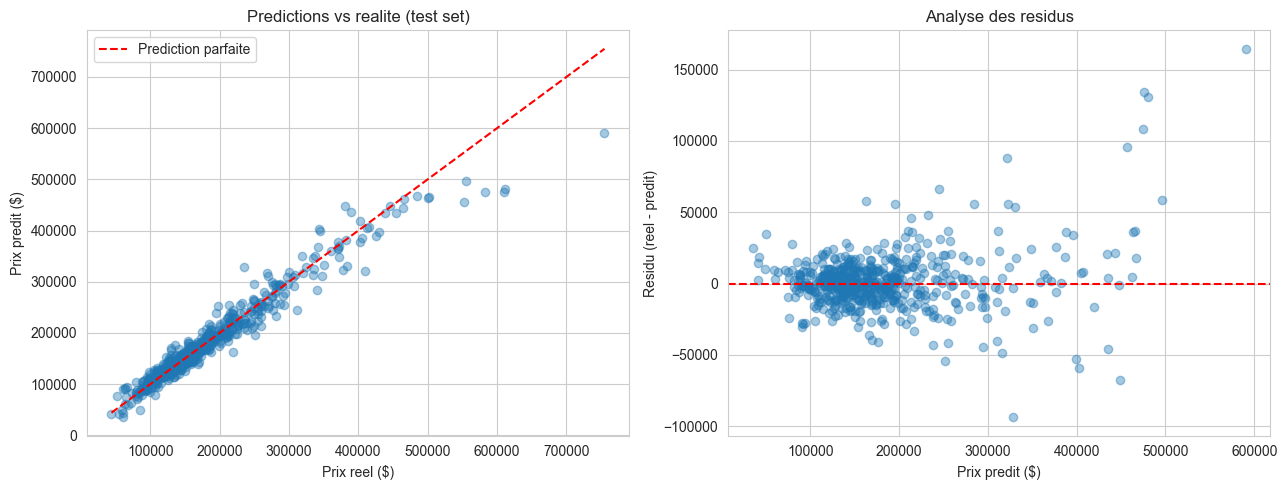

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(price_test, y_pred_price, alpha=0.4)
lims = [price_test.min(), price_test.max()]
axes[0].plot(lims, lims, color="red", linestyle="--", label="Prediction parfaite")
axes[0].set_xlabel("Prix reel ($)")
axes[0].set_ylabel("Prix predit ($)")
axes[0].set_title("Predictions vs realite (test set)")
axes[0].legend()

residuals = price_test.values - y_pred_price
axes[1].scatter(y_pred_price, residuals, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Prix predit ($)")
axes[1].set_ylabel("Residu (reel - predit)")
axes[1].set_title("Analyse des residus")

plt.tight_layout()
plt.show()


## 9. Interpretation des resultats

C'est la partie la plus importante pour la valeur metier : un modele precis mais boite noire ne convainc
pas un agent immobilier ou un vendeur. On veut pouvoir repondre a "pourquoi ce prix ?".

### 9.1 Importance des variables (native au modele)

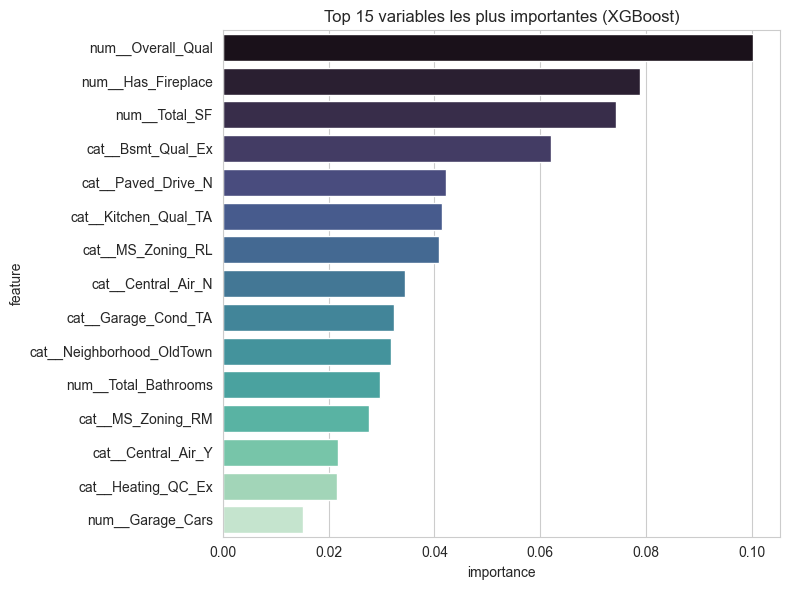

In [ ]:

feature_names = best_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = best_pipe.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({"feature": feature_names, "importance": importances})
importance_df = importance_df.sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df, x="importance", y="feature", hue="feature", palette="mako", legend=False)
plt.title("Top 15 variables les plus importantes (XGBoost)")
plt.tight_layout()
plt.show()


### 9.2 Interpretation fine avec SHAP

L'importance native dit *quelles* variables comptent, mais pas *dans quel sens* ni
*de combien* pour une maison donnee. **SHAP** attribue a chaque
variable, pour chaque prediction individuelle, sa contribution positive ou negative au prix — c'est
l'outil le plus adapte ici car il permet de justifier une estimation maison par maison.

C:\Users\yanni\AppData\Local\Temp\ipykernel_19796\2687114386.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names,


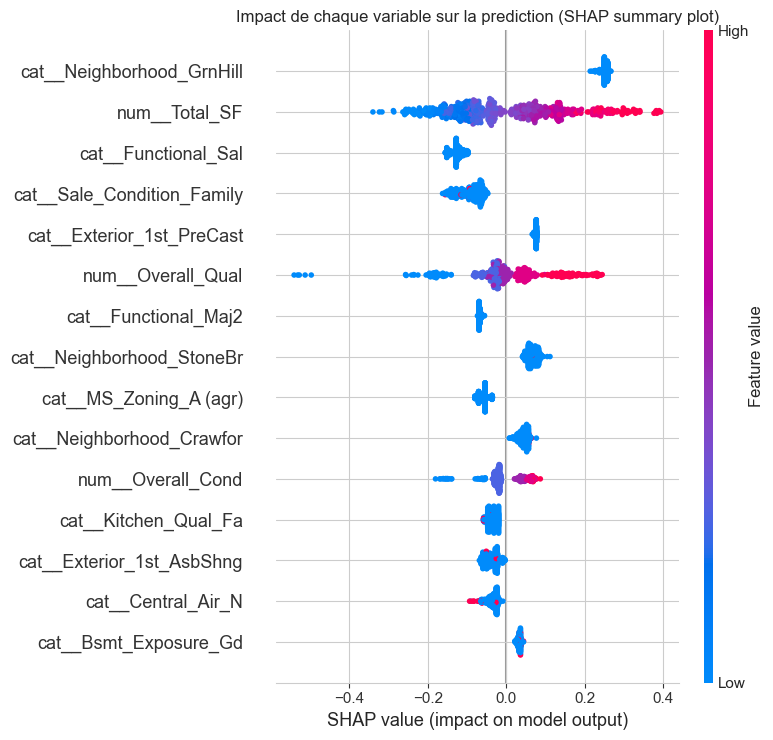

In [ ]:

explainer = shap.TreeExplainer(best_pipe.named_steps["model"])
X_test_transformed = best_pipe.named_steps["preprocessor"].transform(X_test)

# TreeExplainer attend un array dense
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names,
                   max_display=15, show=False)
plt.title("Impact de chaque variable sur la prediction (SHAP summary plot)")
plt.tight_layout()
plt.show()


Maison #0 du test set — prix reel : 298,236 $, prix predit : 295,829 $


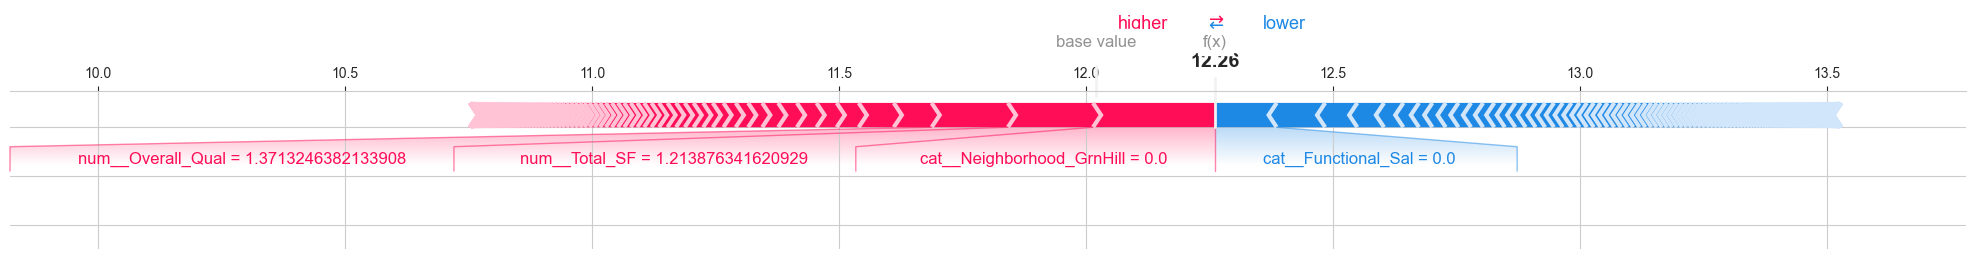

In [ ]:

# focus sur une prediction individuelle : explique le prix d'UNE maison precise du test set
idx = 0
print(f"Maison #{idx} du test set — prix reel : {price_test.iloc[idx]:,.0f} $, "
      f"prix predit : {y_pred_price[idx]:,.0f} $")

shap.force_plot(explainer.expected_value, shap_values[idx], X_test_transformed[idx],
                 feature_names=feature_names, matplotlib=True, show=False)
plt.tight_layout()
plt.show()


Ce type de graphique individuel est directement exploitable dans le POC final : pour n'importe
quelle maison soumise via l'API de deploiement, on peut retourner non seulement le prix estime mais
aussi les 3-4 facteurs qui l'ont le plus fait monter ou baisser — argument commercial concret pour
l'agence immobiliere.

### 9.3 Synthese metier

- Les variables qui dominent (surface totale, qualite globale, quartier, age de la maison) correspondent
  aux criteres qu'un agent immobilier utilise deja intuitivement — le modele **confirme et quantifie**
  une intuition metier plutot que de la contredire, ce qui renforce la confiance qu'on peut lui accorder.
- L'ecart entre RMSE et MAE (RMSE toujours >= MAE) indique la presence de quelques erreurs plus grosses
  que la moyenne, probablement concentrees sur les biens atypiques (tres grandes surfaces, quartiers
  peu representes) — coherent avec le nuage de points de la section 8.
- Le MAPE (% d'erreur relative) est la metrique la plus parlante pour un non-technicien : "le modele se
  trompe en moyenne de X% sur le prix estime" est directement utilisable dans une presentation orale.

## 10. Limites et perspectives

**Limites du dataset :**
- Couverture geographique unique (Ames, Iowa) et periode courte (2006-2010, qui inclut la crise des
  subprimes) : le modele n'est **pas generalisable tel quel** a un autre marche immobilier (autre ville,
  autre pays, autre periode). Il faudrait re-entrainer sur des donnees locales et recentes pour un usage reel.
- Pas de variables macro-economiques (taux d'interet, inflation, marche de l'emploi local) qui influencent
  pourtant fortement les prix immobiliers dans la duree — absence qui limite la capacite du modele a
  anticiper des retournements de marche.
- Pas de coordonnees geographiques precises (uniquement un quartier categoriel), ce qui empeche un
  calcul de proximite fine (distance a une ecole, un centre-ville, etc.).

**Limites du modele :**
- XGBoost/Random Forest, bien que precis, restent moins directement interpretables qu'une regression
  lineaire pure — on compense avec SHAP mais ca reste une explication post-hoc, pas une transparence
  native du modele.
- Pas de quantification de l'incertitude (intervalle de confiance par prediction) dans cette version —
  utile en version 2 (ex: quantile regression, ou forets avec intervalles de prediction).

**Pistes d'amelioration :**
- Stacking / blending de plusieurs modeles (Ridge + XGBoost + RandomForest) pour gagner encore un peu
  de performance.
- Enrichir avec des donnees externes (indice de prix immobilier regional dans le temps -> lien avec la
  tache de prevision de series temporelles du projet global).
- Ajouter un intervalle de confiance a la prediction pour communiquer une fourchette de prix plutot
  qu'un chiffre unique, plus honnete vis-a-vis de l'incertitude reelle du marche.

## 11. Sauvegarde du modele pour deploiement

In [ ]:

import joblib
import os

os.makedirs("../models", exist_ok=True)
joblib.dump(best_pipe, "../models/xgboost_price_pipeline.joblib")
print("Pipeline complet (pretraitement + modele) sauvegarde dans ../models/xgboost_price_pipeline.joblib")
print("Ce fichier unique pourra etre charge tel quel dans l'API FastAPI de deploiement du POC.")


Pipeline complet (pretraitement + modele) sauvegarde dans ../models/xgboost_price_pipeline.joblib
Ce fichier unique pourra etre charge tel quel dans l'API FastAPI de deploiement du POC.
